# 4 · Chapter 4 (4.10–4.11, 4.14): Kane's equations for the motorcycle

Code: `okane/symbolic.py` (SymPy, plays the role of Mathematica in the thesis), `okane/model.py` (numeric assembly), `okane/analysis.py`.

## How this implementation relates to the thesis
The procedure is that of Section 4.10: key points → velocities linear in the generalised speeds → table of partial velocities → $F_r+F_r^*=0$.

* Same bodies, points, frames, co-ordinates $q_1..q_{11}$, speeds $u_r=\dot q_r$ and input vector (Table 4.9).
* As in the thesis the pitch angle is a dependent co-ordinate whose rate is a linear form in the speeds, $\dot\mu=\sum_r H_r u_r$ (4.18).
  The remaining frame co-ordinates $q_{15},q_{16}$ are explicit functions of $(q,\mu)$, so their coefficients ($J$, $K$ of Table 4.6) follow by the chain rule.
* **Deviations** (thesis expressions for the other bodies "are too complex to include" and its parameters are unpublished, so a term-by-term copy is impossible):
  1. $\mu$ and $H_r$ come from the exact loop closure by default (notebook 2); yaw $q_{10}$ is the heading of the frame plane, so $q_{13}=q_{17}=0$.
  2. Nothing is discarded: accelerations include every velocity product and, optionally, the rates of the scheduled coefficients
     (`coef_rates=True`). The thesis' simplified structure $\dot x=Ax+Bu_{in}+Rw$ is then *extracted* from the full model and compared with it.
  3. Tyre forces act on the wheel-fixed point at the true contact point, so $F_x$ automatically produces the wheel torque.
     Axle torques $T_{fwy},T_{rwy}$ are internal (wheel ↔ fork lower / swing-arm), as for a brake.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))   # repo root (not needed after `pip install -e .`)
import numpy as np, sympy as sp, matplotlib.pyplot as plt, time
from scipy.linalg import cholesky
from okane import symbolic
from okane.params import cbr600rr_estimate
from okane.kinematics import make_q
from okane.model import Motorcycle, make_inputs, rk4, INPUTS, IIN, NQ
from okane.forces import ForceSet
from okane.analysis import static_trim, linearise, steady_turn
from okane.plotting import use_style, C
use_style(); np.set_printoptions(linewidth=160, suppress=True, precision=4)
p, design = cbr600rr_estimate()
bike = Motorcycle(p)                     # exact closure, consistent accelerations
F = ForceSet.default(p)                  # gravity + suspension + vertical tyre springs
deg = np.degrees

## 4.10.1 Velocities and partial velocities – body *A* symbolically
`symbolic.build()` returns positions and angular velocities in *N*. With $\dot\mu=\sum H_ru_r$ the partial angular velocities of the main frame are
(compare p. 98 with $F_9=1$, $G_{10}=c_9$, $H_{10}=-s_9$, $G_3=G_4=G_{11}=0$):

In [2]:
r, R, w = symbolic.build()
H = sp.symbols("H1:12")
wA = w["A"].subs(symbolic.mud, sum(h * u for h, u in zip(H, symbolic.u)))
for i in (1, 2, 9, 10, 11):
    print(f"N w_{i}^A =", list(wA.diff(symbolic.u[i - 1]).applyfunc(sp.simplify)))

N w_1^A = [H1*sin(q10)*cos(q9), -H1*sin(q9), H1*cos(q10)*cos(q9)]
N w_2^A = [H2*sin(q10)*cos(q9), -H2*sin(q9), H2*cos(q10)*cos(q9)]
N w_9^A = [H9*sin(q10)*cos(q9) + cos(q10), -H9*sin(q9), H9*cos(q10)*cos(q9) - sin(q10)]
N w_10^A = [H10*sin(q10)*cos(q9), -H10*sin(q9) + 1, H10*cos(q10)*cos(q9)]
N w_11^A = [H11*sin(q10)*cos(q9), -H11*sin(q9), H11*cos(q10)*cos(q9)]


For $r=1,2,11$ this is $H_r(s_{10}c_9,\,-s_9,\,c_9c_{10})$, the printed vectors. For $r=9$ the thesis has $(c_{10},0,-s_{10})$ only – it drops $H_9$
from the angular velocity of *A* although (4.18) contains it; here it is kept. For $r=10$ the printed
$(G_{10}s_9s_{10}+H_{10}s_{10}c_9,\;G_{10}c_9-H_{10}s_9,\;\dots)$ with $G_{10}=c_9$, $H_{10}=-s_9$ collapses to $\hat n_2=(0,1,0)$, which is what comes out below
(the pitch angle does not depend on yaw, so the $H_{10}$ of this code is zero).

The numeric model works with the same objects as arrays: `Jv_X` (3×11) holds the partial velocities of point *X* column by column, `Jw_X` the partial angular velocities.

In [3]:
q_lap = make_q(q1=.076, q2=.137, q3=.005, q4=.008, q9=.493, q11=.028)              # Table 4.7, mean |q|
u_lap = np.array([.038, .068, .012, .016, -113.75, -110.13, 29.26, 0, .314, .244, .625])   # Table 4.7, mean |u|
k = bike.config(q_lap, u_lap)
print("partial velocities of A (rows n1,n2,n3; columns r = 1..11):\n", k["Jv_A"])
print("partial angular velocities of A:\n", k["Jw_A"])

partial velocities of A (rows n1,n2,n3; columns r = 1..11):
 [[-0.2162  0.0536  0.269  -0.269   0.      0.      1.      0.      0.0052  0.3093 -0.0082]
 [ 0.4069  0.2412 -0.5062 -0.4938  0.      0.      0.      0.     -0.2678  0.      0.0154]
 [ 0.2186  0.1296 -0.272  -0.2653  0.      0.      0.      1.      0.598  -0.7012  0.0083]]
partial angular velocities of A:
 [[ 0.      0.      0.      0.      0.      0.      0.      0.      1.      0.      0.    ]
 [-0.3118  0.1895  0.3879 -0.3879  0.      0.      0.      0.      0.0075  1.     -0.0118]
 [ 0.5804 -0.3527 -0.722   0.722   0.      0.      0.      0.     -0.014   0.      0.022 ]]


## 4.10.2 Kane's equations  $K\dot u+f=0$
$$K_{rs}=\sum_{bodies} m\,\mathbf v_r\!\cdot\!\mathbf v_s+\boldsymbol\omega_r\!\cdot\!\mathbf I\,\boldsymbol\omega_s,\qquad
f=\underbrace{c_b(q,u)}_{\text{velocity products}}-\underbrace{B_g(q)}_{-\beta}\,u_{in}$$
$K$ is symmetric positive definite and is solved by Cholesky decomposition (Section 4.14).

In [4]:
K = bike.mass_matrix(k)
print("symmetric:", np.allclose(K, K.T), "  eigenvalues > 0:", np.linalg.eigvalsh(K).min() > 0, "  Cholesky ok:", cholesky(K).shape)
print("\nfirst row of K at the lap-mean state:\n", K[0])
print("\nthesis, coefficients of -F1* in (4.33):  79.668  18.519  -244.277  157.001  0.869  0.931  .  .  1.364  .  -0.078")

symmetric: True   eigenvalues > 0: True   Cholesky ok: (11, 11)

first row of K at the lap-mean state:
 [ 79.769   18.0403 -95.2534 -29.5563   0.3187   0.4203 -43.1777  52.0347   4.5641 -61.657    2.8913]

thesis, coefficients of -F1* in (4.33):  79.668  18.519  -244.277  157.001  0.869  0.931  .  .  1.364  .  -0.078


$K_{11}$ and $K_{12}$ (fork and swing-arm motion against the pitching bike) come out within 3 % of the printed values, which says the estimated mass
distribution is in the right region. The other entries are not comparable: they depend on how $q_3,q_4,q_7..q_{10}$ are defined in detail
(e.g. the thesis row has no coupling of fork motion to $\dot u_7,\dot u_8,\dot u_{10}$, which a leaned bike with *N*-fixed translation speeds must have).

### Size of the velocity-product terms – eqs. (4.33)/(4.34) revisited
$c_b$ is an exact quadratic form in the speeds, $c_{b,r}=\sum_{j\le k}\Gamma_{rjk}u_ju_k$. Evaluating it with the lap-mean speeds of Table 4.7 shows which products matter.

In [5]:
Gam = bike.quadratic_bias(q_lap)
def ranking(row, n=10):
    terms = [(abs(Gam[row, j, kk] * u_lap[j] * u_lap[kk]), j + 1, kk + 1, Gam[row, j, kk]) for j in range(NQ) for kk in range(j, NQ)]
    return sorted(terms, reverse=True)[:n]
for row in (0, 8, 10):
    print(f"\nequation r = {row+1}:   product   coefficient   |value| at lap-mean speeds")
    for val, j, kk, coef in ranking(row, 8):
        print(f"      u{j:<2d} u{kk:<2d} {coef:12.3f} {val:12.4f}")


equation r = 1:   product   coefficient   |value| at lap-mean speeds
      u9  u9       -59.396       5.8562
      u9  u10      -69.892       5.3548
      u9  u11       15.220       2.9869
      u11 u11        2.500       0.9767
      u5  u11       -0.009       0.6347
      u10 u10       10.441       0.6216
      u3  u9      -103.739       0.3909
      u2  u10      -18.345       0.3044

equation r = 9:   product   coefficient   |value| at lap-mean speeds
      u5  u11        0.442      31.3930
      u6  u10        0.562      15.1026
      u5  u10        0.429      11.9067
      u10 u10      -49.707       2.9594
      u1  u9       145.027       1.7305
      u2  u9        80.812       1.7255
      u9  u11        6.970       1.3679
      u4  u9      -187.945       0.9442

equation r = 11:   product   coefficient   |value| at lap-mean speeds
      u5  u9        -0.442      15.7718
      u5  u10       -0.181       5.0236
      u9  u9        -2.457       0.2422
      u9  u10       -2.955   

In the suspension equation ($r=1$) the roll-rate products $u_9^2$, $u_9u_{10}$, $u_9u_{11}$ dominate, as the thesis finds. In the roll and steer equations
the largest terms are products with the wheel spin rates $u_5,u_6$ – the wheel gyroscopic moments, which the thesis places in the $A$ matrix –
followed by yaw-rate and roll-rate products.

## Thesis structure  $\dot x=Ax+Bu_{in}+Rw$  (4.36)–(4.38)
`Motorcycle.state_space(q, u)` extracts, at a scheduling point, $x=[u_1,q_1,\dots,u_{11},q_{11}]$, $w=[u_9^2,\;u_9u_{10},\;u_9u_{11},\;u_{10}u_{11}]$:
* $\alpha$: products containing a (scheduled) wheel spin rate – linear in the other speeds;
* $\gamma$: the four retained products; all other products are dropped;
* $A'=-K^{-1}\alpha$, $B'=K^{-1}B_g$, $R'=-K^{-1}\gamma$, plus the rows $\dot q_r=u_r$.

(The thesis does not print $\alpha$ and $\gamma$; this split is my reading of Sections 4.5 and 4.10.2.)

In [6]:
ss = bike.state_space(q_lap, u_lap)
print("A", ss["A"].shape, " B", ss["B"].shape, " R", ss["R"].shape)
uin = make_inputs(g=9.81, Ffork=1225, Tsay=704.5, Ffwz=1150, Frwz=1527, Ffwy=834, Frwy=833, Tsteer=10)   # magnitudes of Table 4.8
full = bike.accelerations(q_lap, u_lap, uin)
simp = bike.accelerations_thesis(q_lap, u_lap, uin)
const = Motorcycle(p, pitch_model="thesis", coef_rates=False).accelerations(q_lap, u_lap, uin)
print("\n      r:", "".join(f"{i:9d}" for i in range(1, 12)))
print("full   :", "".join(f"{v:9.3f}" for v in full))
print("A,B,R  :", "".join(f"{v:9.3f}" for v in simp))
print("(4.17)+const. coeff.:", "".join(f"{v:8.3f}" for v in const))

A (22, 22)  B (22, 21)  R (22, 4)

      r:         1        2        3        4        5        6        7        8        9       10       11
full   :     7.324  -24.962   12.772  -11.407    0.608   25.480   -1.177    9.273  -10.399   -5.953   61.514
A,B,R  :     7.299  -24.949   12.758  -11.395    0.617   25.476   -1.221    9.268  -10.400   -5.954   61.544
(4.17)+const. coeff.:    7.297 -24.954  10.909 -11.415   0.626  25.490  -1.169   9.271 -10.395  -5.954  61.325


At lap-mean conditions the reduced set of products reproduces the full accelerations closely – the thesis' simplification is justified there.
The third line uses the closed-form pitch (4.17) with constant coefficients; the difference sits mainly in $\dot u_3$.

## 4.11 Output matrix $C$
Rows: $q_1$, $q_2$, body rates of the main frame about $\hat a_1,\hat a_2,\hat a_3$ (rate gyros), $u_5$, $u_6$, $q_9$.
The gyro rows are the partial angular velocities of *A* resolved in *A*; compare with Table 4.10
($\omega_3$: $H_1,H_2,H_3,H_4,H_{10},H_{11}$; $\omega_1$: $F_9c_{14}$, $G_{10}s_{14}$; $\omega_2$: $-F_9s_{14}$, $G_{10}c_{14}$).

In [7]:
Cm = bike.output_matrix(k)
print("gyro rows of C, columns u1..u11:\n", Cm[2:5, 0::2])
print("\nH =", k["H"], "\ncos(q9) =", round(np.cos(q_lap[8]), 4), "  -sin(q9) =", round(-np.sin(q_lap[8]), 4), "  mu = q14 =", round(k["mu"], 5))

gyro rows of C, columns u1..u11:
 [[ 0.     -0.      0.     -0.      0.      0.      0.      0.      1.      0.0022 -0.    ]
 [ 0.      0.     -0.      0.      0.      0.      0.      0.     -0.0025  0.8809 -0.    ]
 [ 0.6588 -0.4004 -0.8196  0.8196  0.      0.      0.      0.     -0.0159 -0.4733  0.0249]]

H = [ 0.6588 -0.4004 -0.8196  0.8196 -0.     -0.     -0.     -0.     -0.0159 -0.      0.0249] 
cos(q9) = 0.8809   -sin(q9) = -0.4733   mu = q14 = 0.00248


# Verification
## V1 – energy conservation
Free motion with gravity and linear (conservative) springs on $q_1..q_4$, started with roll, yaw and steer rates and spinning wheels. Total energy must be constant.
The same run with the thesis' constant-coefficient assumption (`coef_rates=False`) shows what that assumption costs here. Note that this is a deliberately
violent case (nothing holds the bike up, it capsizes from 11° to about 50° of roll within 0.3 s); at lap-mean conditions the effect is small (table above).

full model             max |E-E0| = 6.413e-07 J


constant coefficients  max |E-E0| = 1.373e+03 J


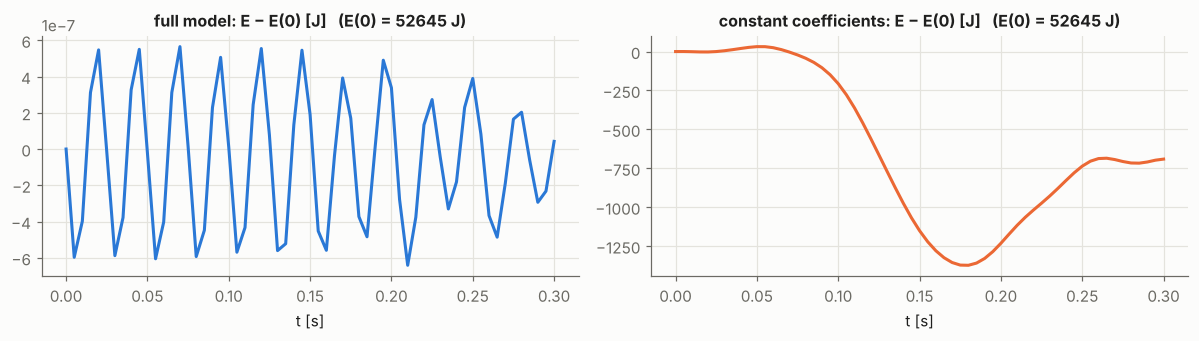

In [8]:
kf, ks, kt = 20e3, 30e3, 180e3
def inp(t, k):
    q = k["q"]
    return make_inputs(g=9.81, Ffork=kf * (0.12 - q[0]), Tsay=ks * (0.2 - q[1]), Ffwz=kt * q[2], Frwz=kt * q[3])
def energy(m, x):
    kk = m.config(x[:11], x[11:]); q = x[:11]
    return m.kinetic_energy(kk) + m.potential_energy(kk) + 0.5*kf*(0.12-q[0])**2 + 0.5*ks*(0.2-q[1])**2 + 0.5*kt*(q[2]**2+q[3]**2)
u0 = np.zeros(11); u0[[4, 5]] = -60; u0[6] = 19; u0[8], u0[9], u0[10], u0[0] = 0.8, 0.5, -0.6, 0.1
x0 = np.concatenate([make_q(q1=0.08, q2=0.15, q3=0.004, q4=0.006, q9=0.2, q11=0.03), u0])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for i, (m, lab) in enumerate([(bike, "full model"), (Motorcycle(p, coef_rates=False), "constant coefficients")]):
    t, X = rk4(lambda t, x: m.rhs(t, x, inp), 0, x0, 2.5e-4, 1200)
    E = np.array([energy(bike, x) for x in X[::20]])
    ax[i].plot(t[::20], E - E[0], color=C[i]); ax[i].set_title(f"{lab}: E − E(0) [J]   (E(0) = {E[0]:.0f} J)"); ax[i].set_xlabel("t [s]")
    print(f"{lab:22s} max |E-E0| = {abs(E-E[0]).max():.3e} J")
plt.tight_layout()

## V2 – static equilibrium
Solve the four in-plane equations for $q_1..q_4$ with the suspension tables of notebook 3 and placeholder vertical tyre springs.
The tyre loads must equal elementary statics (total weight, moment balance about the rear contact point).

In [9]:
q_s, uin_s, res = static_trim(bike, F)
k_s = bike.config(q_s)
cg = bike.kin.mass_centre(k_s)
Fzf_statics = p.total_mass * p.g * (cg[0] - k_s["r_T"][0]) / (k_s["r_S"][0] - k_s["r_T"][0])
print(f"q1 = {q_s[0]*1e3:.1f} mm, q2 = {deg(q_s[1]):.2f}°, q3 = {q_s[2]*1e3:.2f} mm, q4 = {q_s[3]*1e3:.2f} mm, pitch = {deg(k_s['mu']):.3f}°")
print(f"Fz front {uin_s[IIN['Ffwz']]:.2f} N (statics {Fzf_statics:.2f}),  rear {uin_s[IIN['Frwz']]:.2f} N,  sum {uin_s[IIN['Ffwz']]+uin_s[IIN['Frwz']]:.2f} = m g = {p.total_mass*p.g:.2f}")
print(f"front load share {uin_s[IIN['Ffwz']]/(p.total_mass*p.g)*100:.1f} %, c.g. height {cg[1]:.3f} m, fork force {uin_s[IIN['Ffork']]:.0f} N, swing-arm torque {uin_s[IIN['Tsay']]:.0f} N m")
print("max residual of all 11 equations:", abs(res).max())

q1 = 82.2 mm, q2 = 8.97°, q3 = 7.99 mm, q4 = 6.97 mm, pitch = -0.051°
Fz front 1358.74 N (statics 1358.74),  rear 1289.96 N,  sum 2648.70 = m g = 2648.70
front load share 51.3 %, c.g. height 0.606 m, fork force 1076 N, swing-arm torque 612 N m
max residual of all 11 equations: 1.5804441422695715e-13


## V3 – in-plane modes
The suspension and tyre stiffness live in the input blocks, not in $A$ (Section 4.5) – "it will be shown that this issue can be overcome".
The simplest way is to linearise the closed loop *model + force blocks* numerically (`analysis.linearise`).

In [10]:
idx = [0, 1, 2, 3]; ii = idx + [11 + i for i in idx]
for damp in (False, True):
    J = linearise(bike, lambda t, k: F.inputs(t, k, damping=damp), q_s, np.zeros(11))
    ev = np.linalg.eigvals(J[np.ix_(ii, ii)])
    print("\nundamped:" if not damp else "\nwith dampers:")
    for e in sorted(ev[ev.imag >= 0], key=lambda e: abs(e)):
        kind = f"{abs(e.imag)/2/np.pi:6.2f} Hz, zeta = {-e.real/abs(e):.2f}" if abs(e.imag) > 1e-6 else "real"
        print(f"   {e.real:9.2f} {e.imag:+9.2f}j   {kind}")
J = linearise(bike, lambda t, k: F.inputs(t, k), q_s, np.zeros(11))
print("\nfastest pole:", round(np.linalg.eigvals(J).real.min(), 1), "1/s   (thesis: -373.3 1/s, hence its 800 Hz sample rate, Section 4.9)")


undamped:
        0.00    +12.91j     2.05 Hz, zeta = -0.00
        0.00    +22.34j     3.56 Hz, zeta = -0.00
        0.00    +94.19j    14.99 Hz, zeta = -0.00
        0.00   +107.37j    17.09 Hz, zeta = -0.00

with dampers:
       -6.77    +12.04j     1.92 Hz, zeta = 0.49
      -14.75     +0.00j   real
      -36.28    +52.49j     8.35 Hz, zeta = 0.57
      -38.39    +74.73j    11.89 Hz, zeta = 0.46
     -105.28     +0.00j   real

fastest pole: -105.3 1/s   (thesis: -373.3 1/s, hence its 800 Hz sample rate, Section 4.9)


Undamped bounce ≈ 2 Hz, pitch ≈ 3.6 Hz and wheel hop at 15–17 Hz are textbook values for a sports bike, a sanity check of the estimated parameter set and of the
generalised forces.

## V4 – drop test at 800 Hz and 400 Hz (cf. Fig. 4.33)
Bike released with the suspension extended and the tyres just touching the ground. Forward Euler at the thesis' sample rates versus RK4.

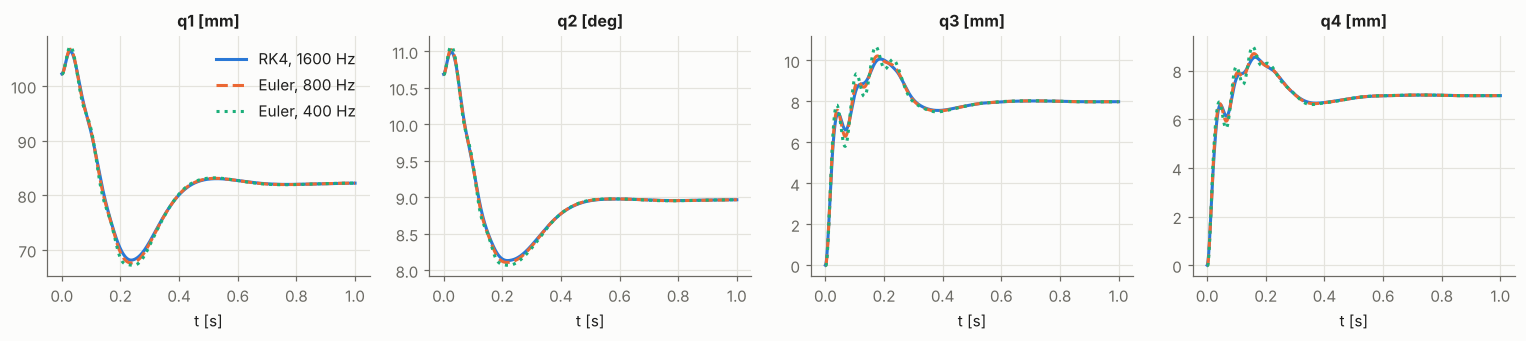

In [11]:
x0 = np.concatenate([q_s, np.zeros(11)]); x0[0] += 0.02; x0[1] += 0.03; x0[2] = x0[3] = 0.0
f = lambda t, x: bike.rhs(t, x, lambda t, k: F.inputs(t, k))
t_ref, X_ref = rk4(f, 0, x0, 1 / 1600, 1600)
def euler(dt, n):
    X = np.empty((n + 1, 22)); X[0] = x0
    for i in range(n): X[i + 1] = X[i] + dt * f(i * dt, X[i])
    return dt * np.arange(n + 1), X
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
runs = [("RK4, 1600 Hz", t_ref, X_ref, "-")] + [(f"Euler, {hz} Hz", *euler(1 / hz, hz), ls) for hz, ls in ((800, "--"), (400, ":"))]
for a, (j, lab, sc) in zip(ax, [(0, "q1 [mm]", 1e3), (1, "q2 [deg]", deg(1)), (2, "q3 [mm]", 1e3), (3, "q4 [mm]", 1e3)]):
    for i, (name, t, X, ls) in enumerate(runs):
        a.plot(t, X[:, j] * sc, ls, color=C[i], label=name)
    a.set_title(lab); a.set_xlabel("t [s]")
ax[0].legend(); plt.tight_layout()

## V5 – steady-state cornering without a tyre model
Prescribe speed and radius, set all relative speeds to zero and let the wheels roll freely. The eleven equations of motion (with the centripetal
$\dot u_7,\dot u_8$) plus zero lateral velocity of the front contact point determine roll angle, steer angle, suspension/tyre deflections,
the tyre side forces needed, and the rider's steering torque. Checks: $\sum F_y=m\,a_{cg}$, $\sum F_z=mg$, and roll angle slightly above
$\arctan(v^2/gR)$ because of the tyre crown radii and wheel gyroscopics.

In [12]:
print("   V     R   | roll  ideal  steer  | Fy_f   Fy_r   m*a_cg | Fz_f   Fz_r  | Tsteer | residual")
for V, Rc in [(15, 40), (20, 60), (30, 80), (40, 150), (55, 400)]:
    s = steady_turn(bike, F, V, Rc, "right"); kk, ui = s["k"], s["u_in"]
    cgp = bike.kin.mass_centre(kk); w_ = s["yaw_rate"]
    a_cg = w_**2 * np.linalg.norm((cgp - np.array([0, 0, -V / w_]))[[0, 2]])
    print(f"{V:5.0f} {Rc:5.0f}  | {deg(s['q'][8]):5.2f} {deg(np.arctan(V**2/9.81/Rc)):6.2f} {deg(s['q'][10]):6.3f} | "
          f"{ui[IIN['Ffwy']]:6.0f} {ui[IIN['Frwy']]:6.0f} {p.total_mass*a_cg:7.0f} | {ui[IIN['Ffwz']]:6.0f} {ui[IIN['Frwz']]:6.0f} | {ui[IIN['Tsteer']]:6.2f} | {abs(s['residual']).max():.1e}")

   V     R   | roll  ideal  steer  | Fy_f   Fy_r   m*a_cg | Fz_f   Fz_r  | Tsteer | residual
   15    40  | 34.10  29.83 -1.782 |    782    724    1506 |   1374   1274 |  -9.82 | 4.0e-16
   20    60  | 39.15  34.20 -1.112 |    930    859    1788 |   1376   1273 | -12.02 | 1.9e-15


   30    80  | 55.61  48.91 -0.599 |   1590   1427    3018 |   1395   1253 | -19.27 | 1.4e-15
   40   150  | 54.06  47.40 -0.333 |   1507   1363    2870 |   1390   1258 | -18.82 | 1.1e-15


   55   400  | 43.26  37.63 -0.157 |   1059    981    2040 |   1375   1274 | -14.30 | 2.3e-16


(Angles in degrees, forces in N, torque in N m; right-hand turns: positive roll, negative steer.) The lateral forces add up to mass × centripetal
acceleration of the mass centre up to the small longitudinal components. The steering torque is what the rider must apply **in the absence of tyre
moments** ($M_z$, $M_x$, twisting torque) – it will change substantially once the Chapter 5 tyre model supplies them.

## 4.14 Computational performance

In [13]:
x = np.concatenate([q_lap, u_lap]); n = 300
t0 = time.perf_counter()
for _ in range(n): bike.rhs(0.0, x, lambda t, k: uin)
dt = (time.perf_counter() - t0) / n
print(f"one evaluation of the full equations of motion: {dt*1e3:.2f} ms  →  {1/dt/800:.2f} × real time at 800 Hz with one evaluation per step (pure Python/NumPy)")

one evaluation of the full equations of motion: 0.90 ms  →  1.39 × real time at 800 Hz with one evaluation per step (pure Python/NumPy)


The thesis reaches 5–6 × real time in C. The generated kinematics (`okane/_generated.py`) are plain scalar expressions and could be compiled
(Numba/C) if that becomes relevant.

## Open points for the next sessions
* Chapter 5: Magic Formula tyre with the measured tyre profile; slip velocities at *S*, *T* (and *U*, *V*) are available from `Jv_S`, `Jv_T`, `Jv_G`, `Jv_D`.
* 4.12–4.13: PID speed / roll controllers, Kalman filter on wheel speeds, traction control and ABS strategies.
* Parameters: replace the estimates in `params.py` and `forces.py`.